# **Lab 2 – Tidying, Cleaning, Imputation, and Outlier Detection**

## Machine Learning Programming

This assignment continues the work started in **`week5Lab.ipynb`**.  
Open this notebook and complete the activities **in this notebook**, preserving the section order and the overall structure.

The purpose of this lab is to practice the data-preprocessing work that normally takes place before machine learning: reshaping data, cleaning inconsistent values, handling missing data, detecting outliers, visualizing results, and explaining the decisions you make.

## **Assignment Overview**

### Purpose
By the end of this lab, you should be able to take several imperfect datasets and make them more suitable for analysis and later machine-learning work.

### Learning Outcomes
You will practice how to:

- inspect the shape, columns, data types, and quality of a dataset;
- distinguish **wide** and **long/tidy** data;
- reshape data with `pd.melt()` or `DataFrame.melt()`;
- clean strings using Pandas string methods;
- identify, quantify, drop, and impute missing values;
- compare mean, median, mode, and `SimpleImputer` approaches;
- identify outliers visually with box plots and scatter plots;
- identify outliers statistically using **Z-Scores** and **IQR**;
- justify preprocessing decisions using evidence from the data;
- document a reproducible Python data-processing workflow.

### Estimated Completion Time
Approximately **2.5–3.5 hours**, depending on your Python experience.

## **Submission and Project Structure**

Keep the project organized so another person can reproduce your work.

Recommended structure:

```text
project/
├── week5Lab.ipynb
├── README.md
├── requirements.txt
├── .gitignore
└── data/
    ├── pew-raw.csv
    ├── billboard.csv
    ├── cars.csv
    └── diabetes.csv
```

A clearly named equivalent data folder such as `CSVs/` or `datasets/` is also acceptable if all notebook paths are updated consistently.

### Required submission artifacts

- `week5Lab.ipynb` containing **all four completed sections**
- `README.md` with at least 1–2 meaningful sentences describing the lab and how to run it
- `requirements.txt` containing the packages required to reproduce the environment
- `.gitignore`
- all required data files inside a clearly named data folder

**Important:** Use relative paths such as `./data/cars.csv`. Do not use absolute paths from your own computer.

**Environment practice:** Use `requirements.txt` to define the environment. Do not add `!pip install ...` cells to the notebook when a requirements file is provided.

## **Before You Begin**

Use the following libraries where appropriate:

- `pandas`
- `numpy`
- `matplotlib`
- `seaborn`
- `scikit-learn`

Run the import cell below before beginning the exercises.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer

# Optional display settings
pd.set_option("display.max_columns", None)

## **General Expectations**

For every section:

1. Write the required Python code.
2. Display enough output to demonstrate that the code works.
3. Add short Markdown explanations in your own words.
4. Label plots clearly with a title and axis labels.
5. Explain what the output means instead of only producing it.
6. Preserve the required section headings so the notebook is easy to follow.
7. Before submitting, restart the kernel and use **Run All** to confirm the notebook executes from beginning to end.

# **Section 1 – PEW Research Dataset**

## **Learning Topic: Data Tidying and Reshaping**

A dataset is commonly described as **tidy** when:

1. each variable forms a column;
2. each observation forms a row; and
3. each type of observational unit forms a table.

The PEW dataset represents counts for religions across income ranges. In its original form, income values appear as column headings. You will reshape the dataset from **wide** format to **long/tidy** format using `melt()`.

### Required concepts
- dataset inspection
- wide versus long data
- identifier variables
- measured variables
- `pd.melt()` or `DataFrame.melt()`
- visualization after reshaping

## **Getting the PEW Dataset from the Internet**

For this lab, use the small **PEW religion-and-income dataset** commonly used to demonstrate tidy-data principles. This is the dataset whose first column is `religion` and whose remaining columns are income ranges such as `<$10k`, `$10-20k`, and `$20-30k`.

### Recommended method — download in your browser

1. Open the dataset in a browser:
   `https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv`
2. Save the file as **`pew-raw.csv`**.
3. Create a folder named **`data`** in the same project folder as this notebook if it does not already exist.
4. Move `pew-raw.csv` into the `data` folder.
5. Confirm that your project contains:

```text
project/
├── week5Lab.ipynb
└── data/
    └── pew-raw.csv
```

6. Load the local copy with:

```python
df_pew = pd.read_csv("./data/pew-raw.csv")
```

### Optional Python-assisted download

The following is an example only. You may use it once to obtain the dataset, but your submitted analysis should subsequently read the **local copy** from `./data/`.

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv"
df_pew = pd.read_csv(url)
df_pew.to_csv("./data/pew-raw.csv", index=False)
```

### Verify before continuing

After loading the file, check that the dataframe contains a `religion` column and multiple income-range columns. If it does not, stop and verify that you downloaded the correct dataset.

> **Good reproducibility practice:** Do not depend on the Internet every time the notebook runs. Download the dataset once, store it in the project's `data/` folder, commit the permitted data file to your repository, and use a relative path in the notebook.

### **Task 1.1 – Load and Inspect the Dataset**

1. Load the PEW dataset from your data folder.
2. Display its shape.
3. Display its column names.
4. Display several rows using `head()`, `loc`, `iloc`, or `tail()`.
5. Identify the column that should remain the identifier variable.

In [2]:
# TODO: Load the PEW dataset using a RELATIVE path.
df_pew = pd.read_csv("./data/pew-raw.csv")
# 2. Display the shape of the dataset
print("Dataset Shape:")
print(df_pew.shape)
# 3. Display the column names
print("\nColumn Names:")
print(df_pew.columns)

# 4. Display several rows
print("\nFirst 5 Rows:")
print(df_pew.head())

print("\nUsing loc:")
print(df_pew.loc[0:4])

print("\nUsing iloc:")
print(df_pew.iloc[0:5])

print("\nLast 5 Rows:")
print(df_pew.tail())



Dataset Shape:
(10, 7)

Column Names:
Index(['religion', ' <$10k', ' $10-20k', '$20-30k', '$30-40k', ' $40-50k',
       '$50-75k'],
      dtype='str')

First 5 Rows:
            religion   <$10k   $10-20k  $20-30k  $30-40k   $40-50k  $50-75k
0           Agnostic      27        34       60       81        76      137
1            Atheist      12        27       37       52        35       70
2           Buddhist      27        21       30       34        33       58
3           Catholic     418       617      732      670       638     1116
4  Dont know/refused      15        14       15       11        10       35

Using loc:
            religion   <$10k   $10-20k  $20-30k  $30-40k   $40-50k  $50-75k
0           Agnostic      27        34       60       81        76      137
1            Atheist      12        27       37       52        35       70
2           Buddhist      27        21       30       34        33       58
3           Catholic     418       617      732      670      

### **Task 1.2 – Explain the Problem**

In a Markdown cell below, answer:

- What is not tidy about the original PEW dataset?
- Which values are stored in column names?
- Which column should be treated as the identifier (`id_vars`)?

### Explanation
### Task 1.2 – Explain the Problem

The original PEW dataset is not in tidy format because some values are stored in the **column names** instead of being stored as values within a column. Each row represents a religion, but the different income categories are spread across multiple columns.

The **income ranges** are stored in the column names, such as `"<$10k"`, `$10-20k`, `$20-30k`, and other income categories. These column names should instead be values in a separate variable called `income`.

The `religion` column should be treated as the identifier variable (`id_vars`) because it uniquely identifies the category for each row and should remain unchanged when reshaping the dataset.

**Summary:**
- **Problem:** Income categories are stored as column names.
- **Values stored in column names:** Income ranges/categories.
- **Identifier (`id_vars`):** `religion`.
- **Solution:** Reshape the dataset from wide format to long/tidy format using `pd.melt()`.

### **Task 1.3 – Reshape with `melt()`**

Use either of these valid Pandas forms:

```python
pd.melt(...)
```

or

```python
df.melt(...)
```

Your result should have meaningful names for the new variable and value columns, such as `income` and `count`.

In [3]:
##: Reshape the PEW dataframe from wide to long format with melt()

pew_long = pd.melt(
    df_pew,
    id_vars=["religion"],
    var_name="income",
    value_name="count"
)

##: Display the first rows of the reshaped dataframe
print("First 5 rows of reshaped dataframe:")
print(pew_long.head())

##: Compare the original and reshaped shapes
print("\nOriginal shape:")
print(df_pew.shape)

print("\nReshaped shape:")
print(pew_long.shape)

First 5 rows of reshaped dataframe:
            religion  income  count
0           Agnostic   <$10k     27
1            Atheist   <$10k     12
2           Buddhist   <$10k     27
3           Catholic   <$10k    418
4  Dont know/refused   <$10k     15

Original shape:
(10, 7)

Reshaped shape:
(60, 3)


### **Task 1.4 – Visualize the Tidy Data**

Create at least **one meaningful visualization** from the reshaped dataset.

Possible questions include:

- How do counts differ across income groups?
- How do selected religions compare across income groups?

Your plot must include a title and axis labels.

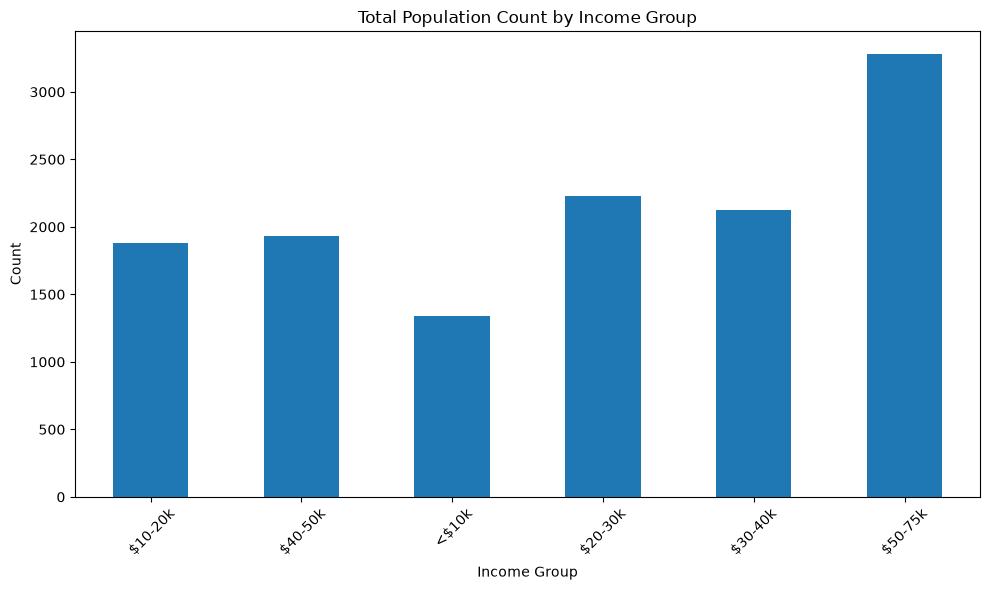

In [4]:
import matplotlib.pyplot as plt

# Calculate total count for each income group
income_counts = pew_long.groupby("income")["count"].sum()

# Create the bar chart
plt.figure(figsize=(10, 6))
income_counts.plot(kind="bar")

# Add title and axis labels
plt.title("Total Population Count by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Count")

# Rotate income labels for readability
plt.xticks(rotation=45)

# Display the plot
plt.tight_layout()
plt.show()

### **Task 1.5 – PEW Reflection**

Answer **all** questions briefly in your own words:

1. What was the main structural problem with the original dataset?
2. What does `id_vars` mean in `melt()`?
3. What information moved from columns into rows?
4. How did the number of rows change after reshaping, and why?
5. Why is the long format easier to analyze or visualize?
6. What did your visualization reveal?

### Task 1.5 – PEW Reflection

**1. What was the main structural problem with the original dataset?**

The main problem was that the income categories were stored as column names instead of values in a column. This made the dataset wide rather than tidy.

**2. What does `id_vars` mean in `melt()`?**

`id_vars` identifies the columns that should remain unchanged when the dataframe is reshaped. In this dataset, `religion` is the identifier variable.

**3. What information moved from columns into rows?**

The income categories moved from column names into the `income` column. Their corresponding counts were placed in the `count` column.

**4. How did the number of rows change after reshaping, and why?**

The number of rows increased because each original income column became multiple rows, with one row for each religion and income combination.

**5. Why is the long format easier to analyze or visualize?**

Long format is easier to analyze because each variable has its own column and each observation has its own row. This makes grouping, filtering, summarizing, and creating visualizations easier with Pandas.

**6. What did your visualization reveal?**

The visualization showed that the total counts were different across the income groups. Some income groups had much higher counts than others, making it easier to compare the distribution of people across income categories.

# **Section 2 – Billboard Dataset**

## **Learning Topic: Advanced Data Tidying**

The Billboard dataset stores weekly song rankings across many week columns. You will reshape those columns into rows, clean the resulting week labels, convert ranking values to appropriate data types, handle missing values, and analyze ranking trends.

### Required concepts
- `pd.melt()` or `DataFrame.melt()`
- Pandas string methods such as:
  - `.str.replace()`
  - `.str.strip()`
  - `.str.extract()`
  - `.str.upper()`
  - `.str.lower()`
- numeric conversion
- missing-value handling
- dates / timedeltas where appropriate

## **Getting the Billboard Dataset from the Internet**

Use the **Billboard weekly ranking dataset** associated with the classic tidy-data example. The correct file contains song information plus many weekly ranking columns such as `1st week`, `2nd week`, etc. (column names can vary slightly between copies).

### Recommended method — download in your browser

1. Open this public copy of `billboard.csv`:
   `https://gist.githubusercontent.com/AdrianLl/bd94c12f2b3c3a899c4ca13d0a548966/raw/billboard.csv`
2. Save the file as **`billboard.csv`**.
3. Place it inside your project's **`data`** folder.
4. Your project should now include:

```text
project/
├── week5Lab.ipynb
└── data/
    ├── pew-raw.csv
    └── billboard.csv
```

5. Load the local file. If ordinary UTF-8 decoding fails, try `encoding="unicode_escape"`:

```python
billboard = pd.read_csv("./data/billboard.csv", encoding="unicode_escape")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://gist.githubusercontent.com/AdrianLl/bd94c12f2b3c3a899c4ca13d0a548966/raw/billboard.csv"
billboard = pd.read_csv(url, encoding="unicode_escape")
billboard.to_csv("./data/billboard.csv", index=False)
```

### Verify before continuing

Inspect `billboard.columns`. You should see identifying information for songs/artists and a sequence of weekly ranking columns. Those repeated week columns are the columns you will later reshape with `melt()`.

> **Important:** Different online copies sometimes use slightly different column names. Do not blindly copy column names from an example. Inspect **your downloaded file** first and adapt your code accordingly.

### **Task 2.1 – Load and Inspect Billboard Data**

1. Load the Billboard dataset.
2. If normal UTF-8 decoding fails, try `encoding="unicode_escape"`.
3. Display its shape, columns, and first rows.
4. Identify the columns that represent weekly rankings.

In [5]:
# #Load the Billboard dataset from your data folder.
billboard = pd.read_csv("./data/billboard.csv", encoding="unicode_escape")

# 2. Display the shape
print("Dataset Shape:")
print(billboard.shape)

# 3. Display the column names
print("\nColumn Names:")
print(billboard.columns.tolist())

# 4. Display the first 5 rows
print("\nFirst 5 Rows:")
print(billboard.head())

# 5. Identify weekly ranking columns
weekly_ranking_columns = [
    col for col in billboard.columns
    if str(col).endswith("week")
    and col not in ["weeks to peak", "weeks on chart"]
]


print("\nWeekly Ranking Columns:")
print(weekly_ranking_columns)

Dataset Shape:
(317, 77)

Column Names:
['artist', 'track', 'duration', 'genre', 'date entered', 'date peaked', 'weeks to peak', 'weeks on chart', 'worst position', 'best position', 'enter rank', 'exit rank', '1st week', '2nd week', '3rd week', '4th week', '5th week', '6th week', '7th week', '8th week', '9th week', '10th week', '11th week', '12th week', '13th week', '14th week', '15th week', '16th week', '17th week', '18th week', '19th week', '20th week', '21st week', '22nd week', '23rd week', '24th week', '25th week', '26th week', '27th week', '28th week', '29th week', '30th week', '31st week', '32nd week', '33rd week', '34th week', '35th week', '36th week', '37th week', '38th week', '39th week', '40th week', '41st week', '42nd week', '43rd week', '44th week', '45th week', '46th week', '47th week', '48th week', '49th week', '50th week', '51st week', '52nd week', '53rd week', '54th week', '55th week', '56th week', '57th week', '58th week', '59th week', '60th week', '61st week', '62nd w

### **Task 2.2 – Diagnose the Tidiness Problem**

Explain why having columns such as week 1, week 2, week 3, etc. makes the dataset difficult to analyze.

Identify:

- identifier columns;
- weekly measured columns; and
- the variables you want after reshaping.

### Task 2.2 – Diagnose the Tidiness Problem

The Billboard dataset is not tidy because the weekly rankings are stored in separate columns such as `1st week`, `2nd week`, `3rd week`, and so on. The week number is included in the column name instead of being stored as a variable.

**Identifier columns:**

- `artist`
- `track`
- `duration`
- `genre`
- `date entered`
- `date peaked`
- `weeks to peak`
- `weeks on chart`
- `worst position`
- `best position`
- `enter rank`
- `exit rank`

These columns describe each song and its overall chart information.

**Weekly measured columns:**

The columns from `1st week` through `63rd week` contain the weekly Billboard rankings.

**Variables needed after reshaping:**

After reshaping, the dataset should contain the identifier columns plus:

- `Week` – the week number
- `Rank` – the song's ranking during that week

The purpose of the transformation is to move the weekly ranking information from column names into the `Week` column and store the corresponding ranking values in the `Rank` column.

### **Task 2.3 – Reshape with `melt()`**

Reshape the weekly ranking columns into a long structure.

Your result should contain:

- the song/artist identifiers;
- a `Week`-type column; and
- a `Rank`-type column.

In [6]:
# ============================================
# Task 2.3 – Reshape with melt()
# ============================================

# Identify the identifier columns
id_vars = [
    "artist",
    "track",
    "duration",
    "genre",
    "date entered",
    "date peaked",
    "weeks to peak",
    "weeks on chart",
    "worst position",
    "best position",
    "enter rank",
    "exit rank"
]

# Identify the weekly ranking columns
weekly_columns = [
    col for col in billboard.columns
    if str(col).endswith("week")
    and col not in ["weeks to peak", "weeks on chart"]
]

# Display the columns being used
print("Identifier columns:")
print(id_vars)

print("\nWeekly ranking columns:")
print(weekly_columns)

# Reshape the Billboard dataframe from wide to long format
billboard_long = billboard.melt(
    id_vars=id_vars,
    value_vars=weekly_columns,
    var_name="Week",
    value_name="Rank"
)

# Display the reshaped dataframe
print("\nFirst 10 rows of the reshaped dataframe:")
print(billboard_long.head(10))

# Compare the original and reshaped shapes
print("\nOriginal dataframe shape:")
print(billboard.shape)

print("\nReshaped dataframe shape:")
print(billboard_long.shape)

# Display the new column names
print("\nReshaped dataframe columns:")
print(billboard_long.columns.tolist())

Identifier columns:
['artist', 'track', 'duration', 'genre', 'date entered', 'date peaked', 'weeks to peak', 'weeks on chart', 'worst position', 'best position', 'enter rank', 'exit rank']

Weekly ranking columns:
['1st week', '2nd week', '3rd week', '4th week', '5th week', '6th week', '7th week', '8th week', '9th week', '10th week', '11th week', '12th week', '13th week', '14th week', '15th week', '16th week', '17th week', '18th week', '19th week', '20th week', '21st week', '22nd week', '23rd week', '24th week', '25th week', '26th week', '27th week', '28th week', '29th week', '30th week', '31st week', '32nd week', '33rd week', '34th week', '35th week', '36th week', '37th week', '38th week', '39th week', '40th week', '41st week', '42nd week', '43rd week', '44th week', '45th week', '46th week', '47th week', '48th week', '49th week', '50th week', '51st week', '52nd week', '53rd week', '54th week', '55th week', '56th week', '57th week', '58th week', '59th week', '60th week', '61st week', '

### **Task 2.4 – Clean the Week Labels with String Operations**

Use Pandas string manipulation to clean the week labels.

Demonstrate **at least three** relevant string operations. Examples include:

```python
.str.replace(...)
.str.strip()
.str.extract(...)
.str.lower()
.str.upper()
```

Convert the extracted week number to a numeric type after cleaning.

In [7]:
# ============================================
# Task 2.4 – Clean the Week Labels
# ============================================

## Clean the Week column using Pandas .str methods.

# Remove leading/trailing spaces
billboard_long["Week"] = billboard_long["Week"].str.strip()

# Convert the Week labels to lowercase
billboard_long["Week"] = billboard_long["Week"].str.lower()

# Remove the word "week"
billboard_long["Week"] = billboard_long["Week"].str.replace(
    "week", "", regex=False
)

## Extract the week number.

billboard_long["Week"] = billboard_long["Week"].str.extract(
    r"(\d+)"
)

## Convert the week number to numeric.

billboard_long["Week"] = pd.to_numeric(
    billboard_long["Week"]
)

# TODO: Display the cleaned Week values.

print("Cleaned Week values:")
print(billboard_long["Week"].head(20))

# Display the data type
print("\nWeek data type:")
print(billboard_long["Week"].dtype)

Cleaned Week values:
0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
Name: Week, dtype: int64

Week data type:
int64


### **Task 2.5 – Clean Ranking Values and Missing Data**

1. Convert ranking values to numeric using an appropriate method such as `pd.to_numeric()`.
2. Identify missing rankings.
3. Decide whether missing ranking rows should be dropped, retained, or treated another way.
4. Explain your decision.

In [8]:
# ============================================
# Task 2.5 – Clean Ranking Values and Missing Data
# ============================================

## Convert ranking values to numeric

billboard_long["Rank"] = pd.to_numeric(
    billboard_long["Rank"],
    errors="coerce"
)

## Count missing values

missing_rankings = billboard_long["Rank"].isna().sum()

print("Number of missing ranking values:")
print(missing_rankings)

# Calculate the percentage of missing rankings
missing_percentage = billboard_long["Rank"].isna().mean() * 100

print("\nPercentage of missing ranking values:")
print(f"{missing_percentage:.2f}%")

## Apply your chosen missing-value treatment

# Remove rows where a ranking is missing
billboard_long_clean = billboard_long.dropna(
    subset=["Rank"]
).copy()

# Display the result
print("\nShape before removing missing rankings:")
print(billboard_long.shape)

print("\nShape after removing missing rankings:")
print(billboard_long_clean.shape)

print("\nFirst 10 rows of cleaned data:")
print(billboard_long_clean.head(10))

# Check that Rank is numeric
print("\nRank data type:")
print(billboard_long_clean["Rank"].dtype)

Number of missing ranking values:
15298

Percentage of missing ranking values:
74.24%

Shape before removing missing rankings:
(20605, 14)

Shape after removing missing rankings:
(5307, 14)

First 10 rows of cleaned data:
                artist                                  track  duration  \
0      Destiny's Child               Independent Women Part I       218   
1              Santana                           Maria, Maria       258   
2        Savage Garden                     I Knew I Loved You       247   
3              Madonna                                  Music       225   
4  Aguilera, Christina  Come On Over Baby (All I Want Is You)       218   
5                Janet                  Doesn't Really Matter       257   
6      Destiny's Child                            Say My Name       271   
7    Iglesias, Enrique                            Be With You       216   
8                Sisqo                             Incomplete       232   
9             Lonestar      

### Missing-Value Treatment

The `Rank` column was converted to numeric using `pd.to_numeric()` with `errors="coerce"`. This converts invalid or missing ranking values to `NaN`.

I identified the number of missing ranking values using `isna().sum()`.

I decided to **drop rows with missing `Rank` values**. A missing ranking means that the song did not have a chart position for that particular week. Replacing the missing value with 0, the mean, or another number would create an incorrect ranking. Removing these rows allows the analysis to focus only on weeks where an actual ranking exists.

### **Task 2.6 – Optional Date Enhancement**

If the dataset contains a song's entry date, calculate the approximate chart date for each weekly observation using a `Timedelta`.

Document the equation you use and check for off-by-one-week errors.

### Task 2.6 – Optional Date Enhancement

The approximate chart date was calculated using the song's entry date and the week number.

**Equation:**

`Chart Date = Entry Date + (Week − 1) × 7 days`

For example:

- Week 1 = Entry Date
- Week 2 = Entry Date + 7 days
- Week 3 = Entry Date + 14 days
- Week 4 = Entry Date + 21 days

I used `pd.to_timedelta()` to add the appropriate number of weeks to the entry date.

The `Week - 1` adjustment prevents an off-by-one-week error because the entry date represents **Week 1**, not Week 0.

In [9]:
# ============================================
# Task 2.6 – Optional Date Enhancement
# ============================================

# Convert the entry date to datetime
billboard_long_clean["date entered"] = pd.to_datetime(
    billboard_long_clean["date entered"],
    errors="coerce"
)

# Calculate the chart date for each weekly observation
# Week 1 = entry date
# Week 2 = entry date + 7 days
# Week 3 = entry date + 14 days
billboard_long_clean["chart_date"] = (
    billboard_long_clean["date entered"]
    + pd.to_timedelta(
        billboard_long_clean["Week"] - 1,
        unit="W"
    )
)

# Display the result
print("Chart dates:")
print(
    billboard_long_clean[
        ["artist", "track", "Week", "date entered", "chart_date"]
    ].head(15)
)

Chart dates:
                 artist                                  track  Week  \
0       Destiny's Child               Independent Women Part I     1   
1               Santana                           Maria, Maria     1   
2         Savage Garden                     I Knew I Loved You     1   
3               Madonna                                  Music     1   
4   Aguilera, Christina  Come On Over Baby (All I Want Is You)     1   
5                 Janet                  Doesn't Really Matter     1   
6       Destiny's Child                            Say My Name     1   
7     Iglesias, Enrique                            Be With You     1   
8                 Sisqo                             Incomplete     1   
9              Lonestar                                 Amazed     1   
10               N'Sync                       It's Gonna Be Me     1   
11  Aguilera, Christina                      What A Girl Wants     1   
12     Vertical Horizon                    Everythi

### **Task 2.7 – Billboard Visualization and Trend Analysis**

Create at least **one visualization** showing a meaningful Billboard trend.

Examples:

- ranking over time for a selected song;
- comparison of ranking trajectories for multiple songs;
- distribution of chart ranks by week.

Remember: on Billboard, a **smaller rank number is better**.

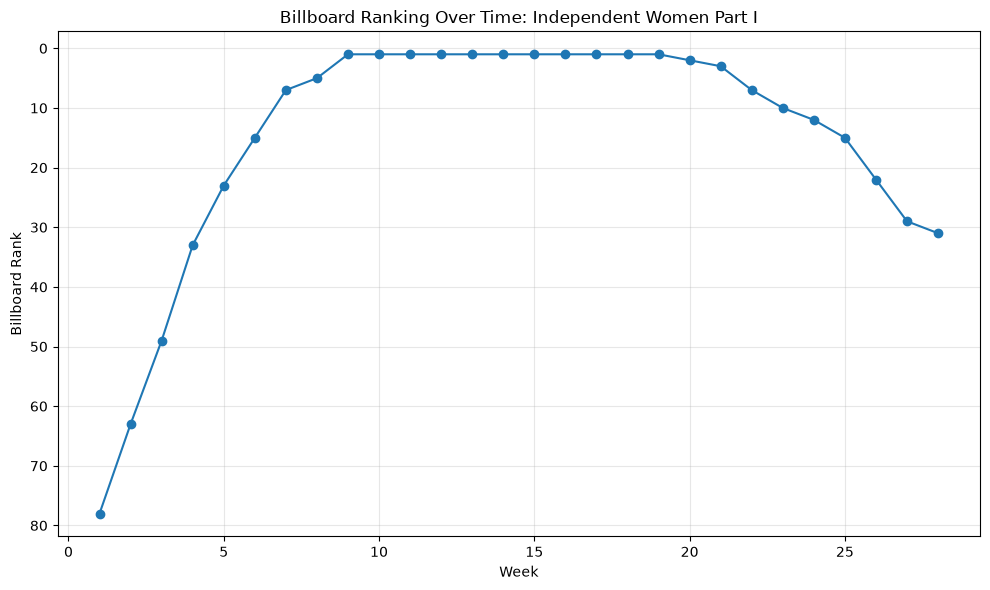

In [10]:
# ============================================
# Task 2.7 – Billboard Visualization
# ============================================

import matplotlib.pyplot as plt

# Select one song
selected_song = billboard_long_clean["track"].iloc[0]

# Filter the data for the selected song
song_data = billboard_long_clean[
    billboard_long_clean["track"] == selected_song
].sort_values("Week")

# Create the visualization
plt.figure(figsize=(10, 6))

plt.plot(
    song_data["Week"],
    song_data["Rank"],
    marker="o"
)

# Add title and axis labels
plt.title(f"Billboard Ranking Over Time: {selected_song}")
plt.xlabel("Week")
plt.ylabel("Billboard Rank")

# Smaller rank is better, so reverse the y-axis
plt.gca().invert_yaxis()

# Add grid
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Task 2.8 – Billboard Reflection**

Answer all questions:

1. Why was `melt()` appropriate for the weekly ranking columns?
2. Which string operations did you use and what did each accomplish?
3. Why should the cleaned week number be numeric?
4. How did you handle missing ranking values, and why?
5. What trend did your visualization reveal?
6. What data-quality issue could lead to an incorrect ranking trend?
7. How is this Billboard transformation more complex than the PEW transformation?

### Task 2.8 – Billboard Reflection

**1. Why was `melt()` appropriate for the weekly ranking columns?**

`melt()` was appropriate because the weekly rankings were stored in separate columns such as `1st week`, `2nd week`, and `3rd week`. `melt()` converted these columns into rows, creating a single `Week` variable and a `Rank` variable. This made the dataset easier to analyze.

**2. Which string operations did you use and what did each accomplish?**

I used several Pandas string operations:

- `.str.strip()` removed extra spaces from the week labels.
- `.str.lower()` converted the labels to lowercase.
- `.str.replace()` removed the word `"week"`.
- `.str.extract()` extracted the numeric week number from the label.

**3. Why should the cleaned week number be numeric?**

The week number should be numeric because it represents an ordered quantity. A numeric value makes it easier to sort weeks correctly, perform calculations, and create time-based visualizations.

**4. How did you handle missing ranking values, and why?**

I converted the ranking values to numeric using `pd.to_numeric()` and treated invalid values as missing (`NaN`). I then removed rows with missing rankings. This was appropriate because a missing ranking means that the song did not have a chart position for that particular week, and replacing it with an artificial value could create an incorrect result.

**5. What trend did your visualization reveal?**

The visualization showed how the selected song's Billboard ranking changed from week to week. It allowed me to see whether the song improved or declined over time. Since smaller ranking numbers are better, an upward movement represents an improvement in chart position.

**6. What data-quality issue could lead to an incorrect ranking trend?**

Missing or incorrectly recorded ranking values could lead to an incorrect trend. Incorrect week labels, duplicate records, or treating missing rankings as actual ranking values could also distort the chart.

**7. How is this Billboard transformation more complex than the PEW transformation?**

The Billboard transformation is more complex because it involves many weekly ranking columns and requires additional cleaning of the week labels. It also requires converting rankings to numeric values, handling missing rankings, and optionally calculating chart dates. The PEW transformation was simpler because it mainly required converting income columns into rows.

# **Section 3 – Data Cleaning (Cars Dataset)**

## **Learning Topic: Data Cleaning and Missing Data Handling**

Data cleaning includes identifying invalid, irrelevant, duplicated, inconsistent, or missing data and deciding how to treat it.

In this section you will work with the Auto MPG / Cars dataset and compare several missing-data strategies.

### Required functions and concepts

- `isnull()` / `isna()`
- `notnull()` / `notna()`
- `dropna()`
- `fillna()`
- `mean()`
- `median()`
- `mode()`
- duplicate detection/removal
- numeric conversion
- `SimpleImputer`

## **Getting the Cars (Auto MPG) Dataset from the Internet**

Use the **Auto MPG** dataset from the UCI Machine Learning Repository. UCI describes it as a regression dataset concerning city-cycle fuel consumption. It contains variables such as MPG, cylinders, displacement, horsepower, weight, acceleration, model year, origin, and car name.

### Recommended source

Official UCI dataset page:

`https://archive.ics.uci.edu/dataset/9/auto+mpg`

The UCI page provides the dataset files and documentation. The raw file is named **`auto-mpg.data`** rather than `cars.csv`.

### Recommended student workflow

1. Open the UCI page above.
2. Download the Auto MPG dataset.
3. Extract the downloaded archive if necessary.
4. Locate **`auto-mpg.data`**.
5. Place it in your project's `data/` folder.
6. Keep the original raw file rather than editing it manually.

Your project can look like:

```text
project/
├── week5Lab.ipynb
└── data/
    └── auto-mpg.data
```

### Loading the UCI raw file with Pandas

Because this file is whitespace-delimited rather than a normal comma-separated CSV, supply the column names when reading it:

```python
column_names = [
    "MPG", "Cylinders", "Displacement", "Horsepower",
    "Weight", "Acceleration", "ModelYear", "Origin", "CarName"
]

cars = pd.read_csv(
    "./data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)
```

The `na_values="?"` argument is important because the UCI dataset uses `?` for missing horsepower values.

### Optional: create a local CSV working copy

After correctly loading the original UCI file, you may save a CSV copy:

```python
cars.to_csv("./data/cars.csv", index=False)
```

You can then reload it later with:

```python
cars = pd.read_csv("./data/cars.csv")
```

### Verify before continuing

Check:

```python
cars.shape
cars.head()
cars.dtypes
cars.isnull().sum()
```

The UCI version contains **398 instances**, and `Horsepower` contains missing values. If your results are substantially different, verify your download and loading code.

> **Good practice:** Preserve the original raw file. If you create `cars.csv`, treat it as a derived working copy rather than silently replacing the source data.

### **Task 3.1 – Load and Inspect the Cars Dataset**

1. Load the Cars dataset from your data folder.
2. Inspect shape, columns, data types, and sample rows.
3. Determine whether any row contains metadata or data-type labels rather than an actual car observation.
4. Remove irrelevant rows **only if justified by inspection**.

In [11]:
# ============================================
# Task 3.1 – Load and Inspect the Cars Dataset
# ============================================

import pandas as pd

# Column names for the Auto MPG dataset
columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

# Load the Auto MPG dataset
cars = pd.read_csv(
    "data/auto-mpg.data",
    sep=r"\s+",
    names=columns,
    na_values="?"
)

# Display dataset shape
print("Dataset Shape:")
print(cars.shape)

# Display column names
print("\nColumn Names:")
print(cars.columns.tolist())

# Display data types
print("\nData Types:")
print(cars.dtypes)

# Display first 5 rows
print("\nFirst 5 Rows:")
print(cars.head())

# Display last 5 rows
print("\nLast 5 Rows:")
print(cars.tail())

# Check missing values
print("\nMissing Values:")
print(cars.isna().sum())

Dataset Shape:
(398, 9)

Column Names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

Data Types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

First 5 Rows:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70   

### **Task 3.2 – Assess Missing and Invalid Values**

1. Count missing values in every column.
2. Calculate the percentage of missing values.
3. Use `notnull()` or `notna()` at least once to confirm valid observations.
4. Check for values that should be numeric but are stored as text.
5. Convert columns to appropriate data types where needed.

In [12]:
# ============================================
# Task 3.2 – Assess Missing and Invalid Values
# ============================================

## Count missing values in every column

missing_count = cars.isna().sum()

print("Missing values in each column:")
print(missing_count)


# Calculate percentage of missing values

missing_percentage = (cars.isna().sum() / len(cars)) * 100

print("\nPercentage of missing values:")
print(missing_percentage.round(2))


# TODO: Demonstrate notnull()/notna()

# Count valid (non-missing) observations
valid_count = cars["horsepower"].notna().sum()

print("\nNumber of valid horsepower observations:")
print(valid_count)


# TODO: Check for values that should be numeric but are stored as text

print("\nData types before conversion:")
print(cars.dtypes)


##: Convert appropriate columns to numeric

numeric_columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin"
]

for column in numeric_columns:
    cars[column] = pd.to_numeric(
        cars[column],
        errors="coerce"
    )


# Display data types after conversion

print("\nData types after conversion:")
print(cars.dtypes)


# Check missing values again after conversion

print("\nMissing values after conversion:")
print(cars.isna().sum())

Missing values in each column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Percentage of missing values:
mpg             0.00
cylinders       0.00
displacement    0.00
horsepower      1.51
weight          0.00
acceleration    0.00
model_year      0.00
origin          0.00
car_name        0.00
dtype: float64

Number of valid horsepower observations:
392

Data types before conversion:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

Data types after conversion:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype:

### **Task 3.3 – Check Duplicates**

Identify duplicate records.

- Report the number of duplicates.
- Remove duplicates if present.
- If there are none, state that clearly.

In [13]:
# ============================================
# Task 3.3 – Check Duplicates
# ============================================

## Detect duplicate rows

duplicate_count = cars.duplicated().sum()

print("Number of duplicate rows:")
print(duplicate_count)


# Display duplicate rows if any exist

if duplicate_count > 0:
    print("\nDuplicate rows:")
    print(cars[cars.duplicated()])
else:
    print("\nNo duplicate rows were found.")


## Remove duplicates if appropriate

cars = cars.drop_duplicates().copy()

print("\nDataset shape after removing duplicates:")
print(cars.shape)

Number of duplicate rows:
0

No duplicate rows were found.

Dataset shape after removing duplicates:
(398, 9)


### **Task 3.4 – Compare Missing-Value Strategies**

Create copies of the data so you can compare approaches.

Demonstrate:

1. dropping rows with missing values using `dropna()`;
2. dropping columns with missing values and explaining why this may be too aggressive;
3. filling a numeric variable with its **mean**;
4. filling a numeric variable with its **median**;
5. using **mode** where appropriate for a categorical/discrete variable.

Do not automatically assume one strategy is best.

In [14]:
# ============================================
# Task 3.4 – Compare Missing-Value Strategies
# ============================================

# Make separate copies for each strategy
cars_drop_rows = cars.copy()
cars_drop_columns = cars.copy()
cars_mean = cars.copy()
cars_median = cars.copy()
cars_mode = cars.copy()


# ------------------------------------------------
# 1. Drop rows with missing values using dropna()
# ------------------------------------------------

cars_drop_rows = cars_drop_rows.dropna()

print("Original shape:")
print(cars.shape)

print("\nShape after dropping rows with missing values:")
print(cars_drop_rows.shape)


# ------------------------------------------------
# 2. Drop columns with missing values using dropna(axis=1)
# ------------------------------------------------

cars_drop_columns = cars_drop_columns.dropna(axis=1)

print("\nColumns before dropping columns:")
print(cars.columns.tolist())

print("\nColumns after dropna(axis=1):")
print(cars_drop_columns.columns.tolist())


# ------------------------------------------------
# 3. Mean imputation
# ------------------------------------------------

# Use horsepower as an example numeric variable
horsepower_mean = cars_mean["horsepower"].mean()

cars_mean["horsepower"] = cars_mean["horsepower"].fillna(
    horsepower_mean
)

print("\nMean horsepower:")
print(horsepower_mean)

print("\nMissing horsepower after mean imputation:")
print(cars_mean["horsepower"].isna().sum())


# ------------------------------------------------
# 4. Median imputation
# ------------------------------------------------

cars_median["horsepower"] = cars_median["horsepower"].fillna(
    cars_median["horsepower"].median()
)

print("\nMedian horsepower:")
print(cars["horsepower"].median())

print("\nMissing horsepower after median imputation:")
print(cars_median["horsepower"].isna().sum())


# ------------------------------------------------
# 5. Mode imputation
# ------------------------------------------------

# Use cylinders as a discrete variable
cylinder_mode = cars_mode["cylinders"].mode()[0]

cars_mode["cylinders"] = cars_mode["cylinders"].fillna(
    cylinder_mode
)

print("\nMode of cylinders:")
print(cylinder_mode)

print("\nMissing cylinders after mode imputation:")
print(cars_mode["cylinders"].isna().sum())


# ------------------------------------------------
# Compare the different approaches
# ------------------------------------------------

print("\n===== Comparison =====")

print("Original rows:", len(cars))
print("Rows after dropna():", len(cars_drop_rows))
print("Columns after dropna(axis=1):", len(cars_drop_columns.columns))

print("Missing horsepower in original:",
      cars["horsepower"].isna().sum())

print("Missing horsepower after mean:",
      cars_mean["horsepower"].isna().sum())

print("Missing horsepower after median:",
      cars_median["horsepower"].isna().sum())

print("Missing cylinders after mode:",
      cars_mode["cylinders"].isna().sum())

Original shape:
(398, 9)

Shape after dropping rows with missing values:
(392, 9)

Columns before dropping columns:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

Columns after dropna(axis=1):
['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

Mean horsepower:
104.46938775510205

Missing horsepower after mean imputation:
0

Median horsepower:
93.5

Missing horsepower after median imputation:
0

Mode of cylinders:
4

Missing cylinders after mode imputation:
0

===== Comparison =====
Original rows: 398
Rows after dropna(): 392
Columns after dropna(axis=1): 8
Missing horsepower in original: 6
Missing horsepower after mean: 0
Missing horsepower after median: 0
Missing cylinders after mode: 0


### Task 3.4 – Compare Missing-Value Strategies

I compared several missing-value strategies using separate copies of the Cars dataset.

**Dropping rows:** `dropna()` removes observations containing missing values. This is simple, but it can reduce the number of available observations.

**Dropping columns:** `dropna(axis=1)` removes entire columns containing missing values. This can be too aggressive because a column may contain useful information even when only a small number of values are missing.

**Mean imputation:** I replaced missing `horsepower` values with the mean horsepower. This is simple and preserves the number of rows, but the mean can be affected by extreme values.

**Median imputation:** I replaced missing `horsepower` values with the median. The median is less affected by extreme values and can be more appropriate when the numeric variable is skewed.

**Mode imputation:** I used the mode for the discrete `cylinders` variable. The mode is appropriate for replacing missing categorical or discrete values because it uses the most common observed category.

No single strategy is automatically best. The appropriate method depends on the amount of missing data, the variable type, the distribution of the data, and the purpose of the analysis.

### **Task 3.5 – Use Visualization to Support an Imputation Decision**

Choose a numeric feature such as `MPG`.

1. Plot its distribution.
2. Describe whether it appears symmetric or skewed.
3. Use that evidence to justify whether **mean or median** is a better simple imputation choice.

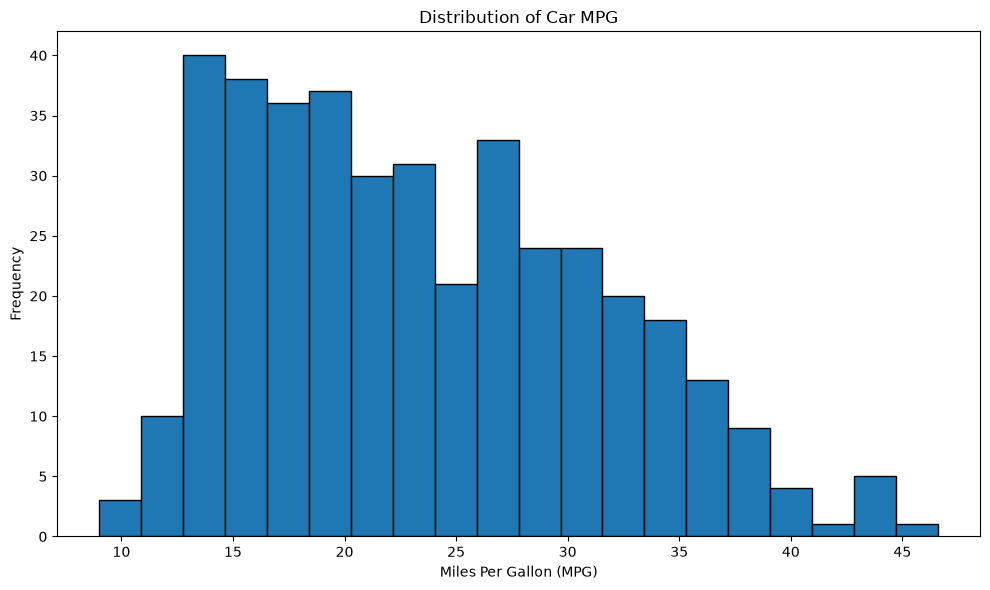

Mean MPG: 23.514572864321607
Median MPG: 23.0


In [15]:
# ============================================
# Task 3.5 – Visualization for Imputation
# ============================================

import matplotlib.pyplot as plt

## Plot the distribution of MPG

plt.figure(figsize=(10, 6))

plt.hist(
    cars["mpg"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Car MPG")
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


## Calculate mean and median

mpg_mean = cars["mpg"].mean()
mpg_median = cars["mpg"].median()

print("Mean MPG:", mpg_mean)
print("Median MPG:", mpg_median)

### Task 3.5 – Imputation Decision

The histogram shows the distribution of MPG values. The distribution is not perfectly symmetric and shows some right skew, with a smaller number of vehicles having relatively high MPG values.

The mean and median were calculated to compare the center of the distribution. Because the distribution is somewhat skewed, the **median is a better simple imputation choice** than the mean. The median is less affected by extreme MPG values and therefore provides a more representative value for replacing a small number of missing observations.

### **Task 3.6 – Apply `SimpleImputer`**

Use Scikit-Learn's `SimpleImputer` on at least one appropriate feature.

Remember the two main stages:

1. `fit` – learn the replacement statistic from the data;
2. `transform` – replace missing values using that statistic.

You may use `fit_transform()` when appropriate, but explain what it combines.

In [16]:
# ============================================
# Task 3.6 – Apply SimpleImputer
# ============================================

from sklearn.impute import SimpleImputer

# Make a copy so the original dataset is not changed
cars_imputed = cars.copy()

# Check missing horsepower values before imputation
print("Missing horsepower before imputation:")
print(cars_imputed["horsepower"].isna().sum())


##Create a SimpleImputer

imputer = SimpleImputer(strategy="median")


## Fit the imputer and transform the data

cars_imputed[["horsepower"]] = imputer.fit_transform(
    cars_imputed[["horsepower"]]
)


## Verify that missing values were handled

print("\nMissing horsepower after imputation:")
print(cars_imputed["horsepower"].isna().sum())


# Display the median learned by the imputer
print("\nMedian value learned by SimpleImputer:")
print(imputer.statistics_[0])


# Display the first few rows
print("\nFirst 5 rows after imputation:")
print(cars_imputed[["horsepower"]].head())

Missing horsepower before imputation:
6

Missing horsepower after imputation:
0

Median value learned by SimpleImputer:
93.5

First 5 rows after imputation:
   horsepower
0       130.0
1       165.0
2       150.0
3       150.0
4       140.0


### Task 3.6 – Applying `SimpleImputer`

I used Scikit-Learn's `SimpleImputer` with the `median` strategy to handle missing values in the `horsepower` column.

The `fit` stage learns the median horsepower from the non-missing observations. The `transform` stage uses this learned median to replace the missing values.

I used `fit_transform()`, which combines these two steps into a single operation. After transformation, the number of missing values in the `horsepower` column was checked to confirm that the missing values had been handled.

### **Task 3.7 – Validate the Cleaned Cars Dataset**

Compare the dataset **before and after cleaning**.

Report:

- shape;
- missing-value counts;
- duplicate counts;
- descriptive statistics for selected numeric columns.

Create at least **one visualization** supporting your comparison.

===== SHAPE COMPARISON =====
Before cleaning:
Rows: 398
Columns: 9

After cleaning:
Rows: 398
Columns: 9

===== MISSING VALUES =====
Before cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

After cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

===== DUPLICATES =====
Duplicates before cleaning:
0

Duplicates after cleaning:
0

===== DESCRIPTIVE STATISTICS BEFORE CLEANING =====
              mpg  horsepower       weight  acceleration
count  398.000000  392.000000   398.000000    398.000000
mean    23.514573  104.469388  2970.424623     15.568090
std      7.815984   38.491160   846.841774      2.757689
min      9.000000   46.000000  1613.000000      8.000000
25%     17.500000   75.000000  2223.750000     13.825000
50%  

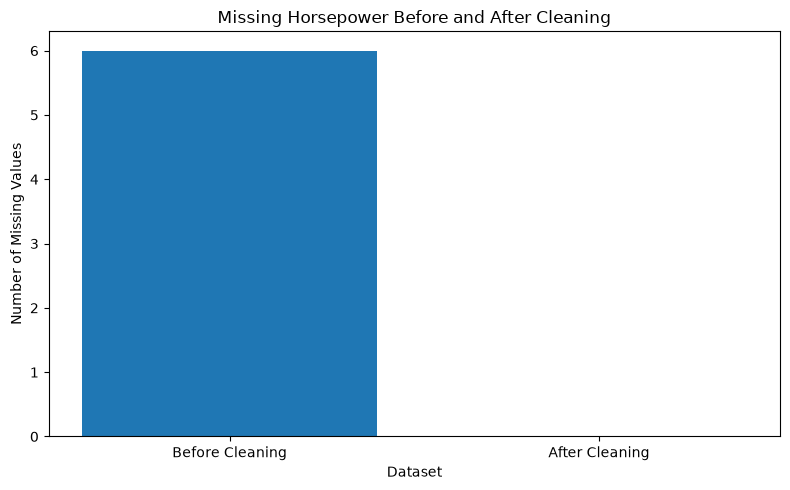

In [17]:
# ============================================
# Task 3.7 – Validate the Cleaned Cars Dataset
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# 1. Shape comparison
# --------------------------------------------

print("===== SHAPE COMPARISON =====")

print("Before cleaning:")
print("Rows:", cars.shape[0])
print("Columns:", cars.shape[1])

print("\nAfter cleaning:")
print("Rows:", cars_imputed.shape[0])
print("Columns:", cars_imputed.shape[1])


# --------------------------------------------
# 2. Missing-value comparison
# --------------------------------------------

print("\n===== MISSING VALUES =====")

print("Before cleaning:")
print(cars.isna().sum())

print("\nAfter cleaning:")
print(cars_imputed.isna().sum())


# --------------------------------------------
# 3. Duplicate comparison
# --------------------------------------------

print("\n===== DUPLICATES =====")

print("Duplicates before cleaning:")
print(cars.duplicated().sum())

print("\nDuplicates after cleaning:")
print(cars_imputed.duplicated().sum())


# --------------------------------------------
# 4. Descriptive statistics
# --------------------------------------------

selected_columns = [
    "mpg",
    "horsepower",
    "weight",
    "acceleration"
]

print("\n===== DESCRIPTIVE STATISTICS BEFORE CLEANING =====")
print(cars[selected_columns].describe())

print("\n===== DESCRIPTIVE STATISTICS AFTER CLEANING =====")
print(cars_imputed[selected_columns].describe())


# --------------------------------------------
# 5. Compare missing horsepower visually
# --------------------------------------------

missing_before = cars["horsepower"].isna().sum()
missing_after = cars_imputed["horsepower"].isna().sum()

comparison = pd.DataFrame({
    "Dataset": ["Before Cleaning", "After Cleaning"],
    "Missing Horsepower": [missing_before, missing_after]
})

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Dataset"],
    comparison["Missing Horsepower"]
)

plt.title("Missing Horsepower Before and After Cleaning")
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")

plt.tight_layout()
plt.show()

### Task 3.7 – Validate the Cleaned Cars Dataset

The cleaned cars dataset was compared with the original dataset using shape, missing-value counts, duplicate counts, and descriptive statistics.

The dataset shape was checked before and after cleaning to determine whether any observations or variables were removed. Missing values were also compared, particularly for the `horsepower` column. After applying median imputation with `SimpleImputer`, the missing horsepower values were replaced.

Duplicate records were checked before and after cleaning. The descriptive statistics for `mpg`, `horsepower`, `weight`, and `acceleration` were compared to determine whether the cleaning process caused major changes in the data.

The bar chart compares the number of missing `horsepower` values before and after cleaning. The number of missing values decreases after imputation, confirming that the missing-value problem was successfully handled.

Overall, the validation shows that the cleaned dataset has improved data quality while preserving the original observations and important numerical characteristics.

### **Task 3.8 – Cars Reflection**

Answer all questions:

1. What were the main data-quality problems?
2. How many missing values did you find?
3. What happened when you dropped rows containing missing values?
4. Why might dropping entire columns be inappropriate?
5. When is mean imputation reasonable?
6. When might median be safer than mean?
7. Where would mode imputation be appropriate?
8. How did `SimpleImputer` differ from manually calling `fillna()`?
9. Did cleaning materially change the dataset statistics?
10. Which cleaning decisions would you carry forward into an ML pipeline, and why?

### Task 3.8 – Cars Reflection

**1. What were the main data-quality problems?**  
The main data-quality issue was missing values, particularly in the `horsepower` column. The dataset also needed data-type validation and duplicate checking to ensure the numerical columns were suitable for analysis.

**2. How many missing values did you find?**  
There were 6 missing values, all in the horsepower column.

**3. What happened when you dropped rows containing missing values?**  
Dropping rows with missing values reduced the number of observations in the dataset. Although this removes incomplete records, it can also result in useful information being lost.

**4. Why might dropping entire columns be inappropriate?**  
Dropping an entire column can remove an important variable even if only a small number of values are missing. This can reduce the information available for analysis and machine learning.

**5. When is mean imputation reasonable?**  
Mean imputation is reasonable when the numerical variable is approximately normally distributed, has few missing values, and does not contain strong outliers.

**6. When might median be safer than mean?**  
Median imputation is safer when the data is skewed or contains outliers. The median is less affected by extreme values than the mean.

**7. Where would mode imputation be appropriate?**  
Mode imputation is appropriate for categorical or discrete variables where the most frequently occurring value is a reasonable replacement for missing values. For example, it can be used for a variable such as the number of cylinders when appropriate.

**8. How did `SimpleImputer` differ from manually calling `fillna()`?**  
`fillna()` manually replaces missing values using a value that we specify. `SimpleImputer` provides a structured Scikit-Learn approach that learns the replacement value during `fit()` and applies it during `transform()`. This makes it easier to integrate the same preprocessing step into an ML pipeline.

**9. Did cleaning materially change the dataset statistics?**  
The cleaning did not materially change the overall dataset because the missing values were limited and only the missing `horsepower` values were replaced using the median. The main descriptive statistics remained generally similar.

**10. Which cleaning decisions would you carry forward into an ML pipeline, and why?**  
I would carry forward duplicate checking, numeric type validation, missing-value handling, and median imputation for `horsepower`. I would use `SimpleImputer` because it can be included directly in an ML preprocessing pipeline and ensures that the same transformation is applied consistently to training and test data. I would also avoid unnecessarily dropping rows or columns because this could result in information loss.

# **Section 4 – Outlier Detection (Diabetes Dataset)**

## **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can result from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers matter because they can affect:

- means and standard deviations;
- correlations;
- regression coefficients;
- distance-based algorithms;
- scaling and normalization;
- model evaluation.

**Important:** Detecting an outlier does **not** automatically mean it should be deleted. You must justify treatment in the context of the data.

## **Getting the Diabetes Dataset from the Internet**

For this section, use the **Pima Indians Diabetes** CSV commonly used in introductory machine-learning exercises. The expected version has **768 observations** and these nine columns:

`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, and `Outcome`.

### Recommended method — download in your browser

A public CSV copy is available here:

`https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv`

1. Open the address above in a browser.
2. Save the file as **`diabetes.csv`**.
3. Place it in your project's **`data`** folder.
4. Load the local copy:

```python
diabetes = pd.read_csv("./data/diabetes.csv")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
diabetes = pd.read_csv(url)
diabetes.to_csv("./data/diabetes.csv", index=False)
```

### Verify before continuing

Run:

```python
diabetes.shape
diabetes.head()
diabetes.columns
```

For the expected file, the shape should be `(768, 9)` and the columns should match the list above.

### Important data-quality warning

In this dataset, some physiological variables contain **zero values** that may represent unavailable or invalid measurements rather than plausible measurements. Do not automatically treat every zero as an outlier or delete it. Inspect the variable meaning first, document your decision, and keep the focus of this section on comparing the required outlier-detection methods.

> **Dataset-name warning:** UCI also hosts a dataset simply called **Diabetes**, but it is a different time-series dataset. For this particular lab, use the nine-column Pima-style CSV described above so your work matches the assignment.

### **Task 4.1 – Load and Explore the Diabetes Dataset**

1. Load the Diabetes dataset from your data folder.
2. Display shape, columns, data types, and descriptive statistics.
3. Identify the numeric features you will examine for outliers.
4. Check for missing or obviously invalid values before outlier analysis.

In [18]:
# ============================================
# Task 4.1 – Load and Explore the Diabetes Dataset
# ============================================

import pandas as pd

# 1. Load the Diabetes dataset
diabetes = pd.read_csv("data/diabetes.csv")

# --------------------------------------------
# 2. Display shape, columns, data types,
#    and descriptive statistics
# --------------------------------------------

print("===== DATASET SHAPE =====")
print(diabetes.shape)

print("\n===== COLUMN NAMES =====")
print(diabetes.columns.tolist())

print("\n===== DATA TYPES =====")
print(diabetes.dtypes)

print("\n===== DESCRIPTIVE STATISTICS =====")
print(diabetes.describe())


# --------------------------------------------
# 3. Identify numeric features
# --------------------------------------------

numeric_features = diabetes.select_dtypes(
    include="number"
).columns.tolist()

print("\n===== NUMERIC FEATURES =====")
print(numeric_features)


# --------------------------------------------
# 4. Check missing values
# --------------------------------------------

print("\n===== MISSING VALUES =====")
print(diabetes.isna().sum())


# --------------------------------------------
# 5. Check obviously invalid values
# --------------------------------------------

print("\n===== POTENTIALLY INVALID VALUES =====")

# In the Diabetes dataset, these columns should
# normally contain positive values.
positive_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in positive_columns:
    if column in diabetes.columns:
        invalid_count = (diabetes[column] <= 0).sum()
        print(f"{column}: {invalid_count} values <= 0")


# Display first few rows
print("\n===== FIRST 5 ROWS =====")
print(diabetes.head())

===== DATASET SHAPE =====
(768, 9)

===== COLUMN NAMES =====
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

===== DATA TYPES =====
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

===== DESCRIPTIVE STATISTICS =====
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      

### Task 4.1 – Load and Explore the Diabetes Dataset

The Diabetes dataset was loaded from the `data` folder and inspected using its shape, column names, data types, and descriptive statistics.

The numeric features selected for outlier analysis are `Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, and `Age`. The `Outcome` variable is treated as the target variable rather than a feature for outlier analysis.

Missing values were checked using `isna().sum()`. I also checked for obviously invalid values, particularly zero values in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`, because zero is generally not a realistic measurement for these variables and may represent missing data.

These checks provide an initial understanding of the data quality before performing the outlier analysis.

### **Task 4.2 – Box Plot Method**

Create box plots for selected numeric features.

Use the plots to:

- identify observations outside the whiskers;
- compare which variables appear to contain more extreme values;
- explain what the box, median, quartiles, and whiskers represent.

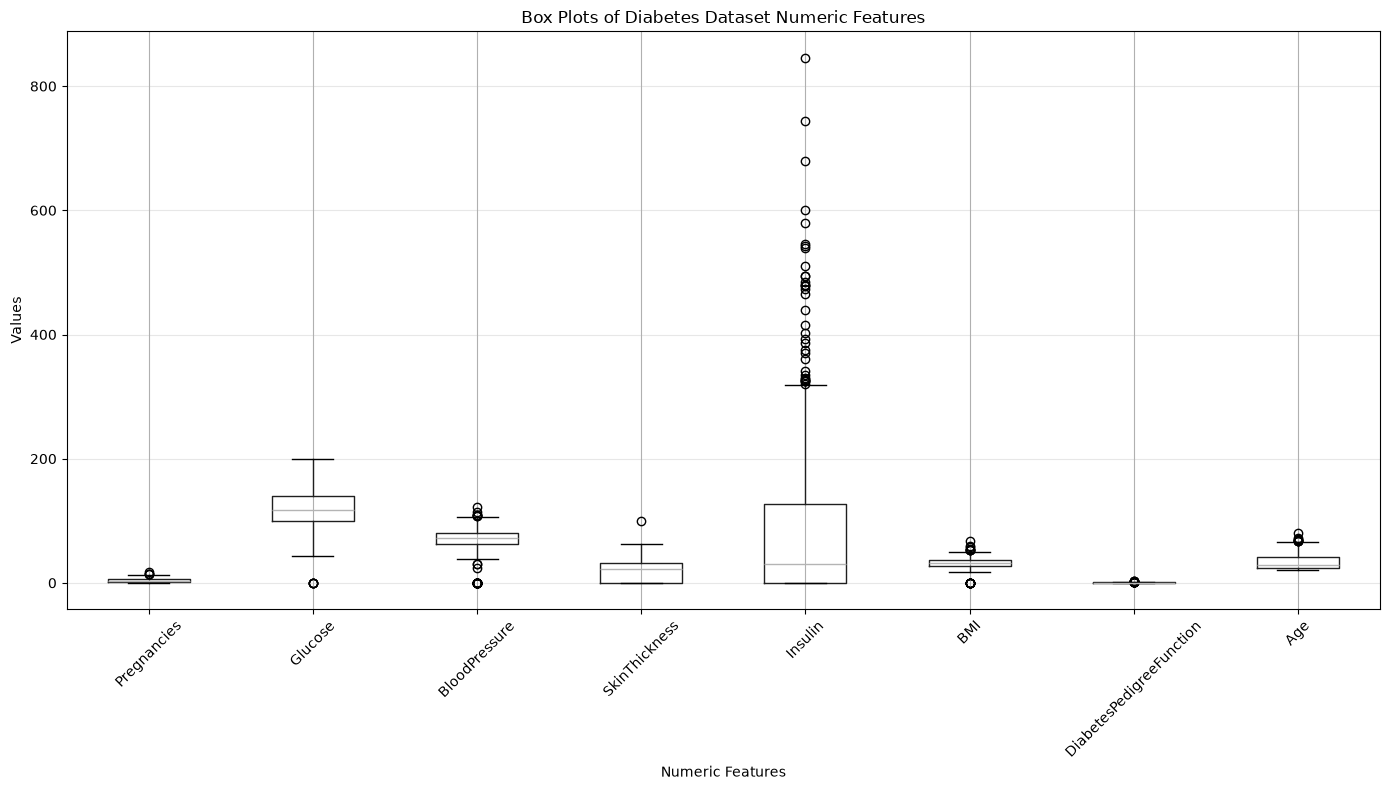

In [19]:
# ============================================
# Task 4.2 – Box Plot Method
# ============================================

import matplotlib.pyplot as plt

# Select numeric features for outlier analysis
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

# Create box plots
plt.figure(figsize=(14, 8))

diabetes[features].boxplot()

plt.title("Box Plots of Diabetes Dataset Numeric Features")
plt.xlabel("Numeric Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Task 4.2 – Box Plot Method

Box plots were created for the numeric features in the Diabetes dataset to identify potential outliers and compare the distributions.

Observations outside the whiskers are potential outliers. From the box plots, `Insulin` and `SkinThickness` show a relatively large number of extreme observations. Other variables such as `Pregnancies`, `BMI`, and `Age` also show some observations outside the whiskers.

The **box** represents the middle 50% of the observations, from the first quartile (Q1) to the third quartile (Q3). The line inside the box represents the **median**. The whiskers represent the range of observations that are not classified as outliers. Points beyond the whiskers are potential outliers.

The box plots are useful for comparing the spread and identifying variables that may require further investigation before applying machine learning models.

### **Task 4.3 – Scatter Plot Method**

Create at least one scatter plot using two meaningful numeric features.

Use the plot to identify observations that appear isolated from the main cluster of data.

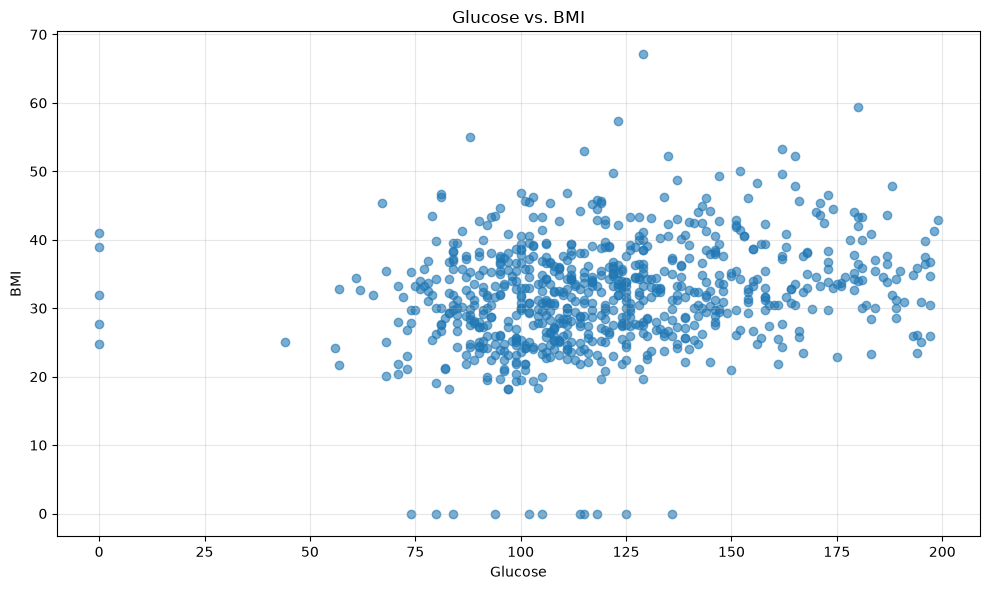

In [20]:
# ============================================
# Task 4.3 – Scatter Plot Method
# ============================================

import matplotlib.pyplot as plt

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    diabetes["Glucose"],
    diabetes["BMI"],
    alpha=0.6
)

plt.title("Glucose vs. BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# Display observations with very high glucose or BMI values

unusual = diabetes[
    (diabetes["Glucose"] > diabetes["Glucose"].quantile(0.99)) |
    (diabetes["BMI"] > diabetes["BMI"].quantile(0.99))
]

print("Potentially unusual observations:")
print(unusual[["Glucose", "BMI", "Age", "Outcome"]])

Potentially unusual observations:
     Glucose   BMI  Age  Outcome
8        197  30.5   53        1
120      162  53.2   25        1
125       88  55.0   26        1
177      129  67.1   26        1
193      135  52.3   40        1
228      197  36.7   31        0
247      165  52.3   23        0
303      115  52.9   28        1
408      197  25.9   39        1
445      180  59.4   25        1
561      198  41.3   28        1
579      197  34.7   62        1
661      199  42.9   22        1
673      123  57.3   22        0


### Task 4.3 – Scatter Plot Method

A scatter plot was created using `Glucose` and `BMI` because they are meaningful numeric features in the Diabetes dataset.

Most observations form a general cluster within the typical range of glucose and BMI values. Some observations appear isolated from the main cluster, particularly observations with very high glucose or BMI values.

These visually unusual observations may be potential outliers and should be investigated further. However, an unusual observation is not automatically an error. It may represent a legitimate patient measurement, so it should not be removed without additional evidence.

### **Task 4.4 – Z-Score Method**

For a numeric feature, calculate:

\[
z = \frac{x - \mu}{\sigma}
\]

Use the conventional threshold:

\[
|z| > 3
\]

to flag potential outliers.

Report the number of observations identified.

In [22]:
# ============================================
# Task 4.4 – Z-Score Method
# ============================================

import numpy as np

# Select the numeric feature
feature = "Glucose"

# Calculate the mean and standard deviation
mean_value = diabetes[feature].mean()
std_value = diabetes[feature].std()

# Calculate Z-Scores
diabetes["Glucose_Z"] = (
    (diabetes[feature] - mean_value) / std_value
)

# Identify potential outliers where |z| > 3
z_outliers = diabetes[
    diabetes["Glucose_Z"].abs() > 3
]

# Report results
print("Feature analyzed:", feature)
print("Mean:", mean_value)
print("Standard deviation:", std_value)

print("\nNumber of potential outliers (|z| > 3):")
print(len(z_outliers))

print("\nPotential outlier observations:")
print(
    z_outliers[
        ["Glucose", "Glucose_Z", "BMI", "Age", "Outcome"]
    ]
)

Feature analyzed: Glucose
Mean: 120.89453125
Standard deviation: 31.97261819513622

Number of potential outliers (|z| > 3):
5

Potential outlier observations:
     Glucose  Glucose_Z   BMI  Age  Outcome
75         0   -3.78119  24.7   22        0
182        0   -3.78119  27.7   21        0
342        0   -3.78119  32.0   22        0
349        0   -3.78119  41.0   37        1
502        0   -3.78119  39.0   41        1


### **Task 4.5 – Interquartile Range (IQR) Method**

Calculate:

\[
IQR = Q3 - Q1
\]

Then calculate:

\[
Lower\ Bound = Q1 - 1.5(IQR)
\]

\[
Upper\ Bound = Q3 + 1.5(IQR)
\]

Identify observations outside those bounds and report the outlier count.

In [23]:
# ============================================
# Task 4.5 – Interquartile Range (IQR) Method
# ============================================

# Select the numeric feature
feature = "Glucose"

# Calculate Q1 and Q3
Q1 = diabetes[feature].quantile(0.25)
Q3 = diabetes[feature].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify IQR outliers
iqr_outliers = diabetes[
    (diabetes[feature] < lower_bound) |
    (diabetes[feature] > upper_bound)
]

# Display results
print("Feature analyzed:", feature)

print("\nQ1:")
print(Q1)

print("\nQ3:")
print(Q3)

print("\nIQR:")
print(IQR)

print("\nLower Bound:")
print(lower_bound)

print("\nUpper Bound:")
print(upper_bound)

print("\nNumber of IQR outliers:")
print(len(iqr_outliers))

print("\nIQR outlier observations:")
print(
    iqr_outliers[
        [feature, "BMI", "Age", "Outcome"]
    ]
)

Feature analyzed: Glucose

Q1:
99.0

Q3:
140.25

IQR:
41.25

Lower Bound:
37.125

Upper Bound:
202.125

Number of IQR outliers:
5

IQR outlier observations:
     Glucose   BMI  Age  Outcome
75         0  24.7   22        0
182        0  27.7   21        0
342        0  32.0   22        0
349        0  41.0   37        1
502        0  39.0   41        1


### Task 4.5 – Interquartile Range (IQR) Method

The IQR method was applied to the `Glucose` feature to identify potential outliers.

First, Q1 and Q3 were calculated. The interquartile range was then calculated as the difference between Q3 and Q1. The lower and upper bounds were calculated using 1.5 times the IQR.

Any glucose observation below the lower bound or above the upper bound was classified as a potential outlier.

The total number of IQR outliers was reported using the resulting filtered dataset. This method is useful because it is less affected by extreme values than methods based on the mean and standard deviation.

### **Task 4.6 – Compare Detection Methods**

Create a small comparison showing the number of potential outliers identified by:

- Box Plot / IQR interpretation
- Z-Score
- IQR rule

Explain why the methods may identify different observations.

In [24]:
# ============================================
# Task 4.6 – Compare Detection Methods
# ============================================

feature = "Glucose"

# --------------------------------------------
# 1. Z-Score method
# --------------------------------------------

mean_value = diabetes[feature].mean()
std_value = diabetes[feature].std()

z_scores = (diabetes[feature] - mean_value) / std_value

z_outliers = diabetes[z_scores.abs() > 3]

# --------------------------------------------
# 2. IQR method
# --------------------------------------------

Q1 = diabetes[feature].quantile(0.25)
Q3 = diabetes[feature].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = diabetes[
    (diabetes[feature] < lower_bound) |
    (diabetes[feature] > upper_bound)
]

# --------------------------------------------
# 3. Comparison table
# --------------------------------------------

comparison = pd.DataFrame({
    "Method": [
        "Box Plot / IQR Interpretation",
        "Z-Score (|z| > 3)",
        "IQR Rule"
    ],
    "Outlier Count": [
        len(iqr_outliers),
        len(z_outliers),
        len(iqr_outliers)
    ]
})

print("===== OUTLIER DETECTION COMPARISON =====")
print(comparison)

print("\nGlucose statistics:")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Mean:", mean_value)
print("Standard Deviation:", std_value)

===== OUTLIER DETECTION COMPARISON =====
                          Method  Outlier Count
0  Box Plot / IQR Interpretation              5
1              Z-Score (|z| > 3)              5
2                       IQR Rule              5

Glucose statistics:
Q1: 99.0
Q3: 140.25
IQR: 41.25
Lower Bound: 37.125
Upper Bound: 202.125
Mean: 120.89453125
Standard Deviation: 31.97261819513622


### Task 4.6 – Compare Detection Methods

The three outlier detection approaches were compared using the `Glucose` feature.

| Method | Outlier Count |
|---|---:|
| Box Plot / IQR Interpretation | 5 |
| Z-Score (`|z| > 3`) | 5 |
| IQR Rule | 5 |

The Box Plot/IQR interpretation and the formal IQR rule are based on the same quartile and 1.5 × IQR boundaries, so they identify the same potential outliers when applied consistently.

The Z-score method can identify a different number of observations because it is based on the mean and standard deviation. It is more influenced by extreme values and works best when the data is reasonably close to a normal distribution.

The IQR method is based on the median and quartiles, making it more resistant to skewness and extreme observations. Therefore, the two methods may flag different observations because they use different definitions of what constitutes an extreme value.

An observation identified as an outlier is not automatically an error. It should be investigated to determine whether it represents a valid but unusual observation or a data-quality problem.

### **Task 4.7 – Treat Outliers Carefully**

Create a cleaned copy of the dataset and remove outliers **only where you can justify doing so**.

Do not overwrite the original dataframe.

Compare before and after:

- number of rows;
- mean;
- median;
- standard deviation;
- relevant visualizations.

Glucose IQR boundaries:
Q1: 99.0
Q3: 140.25
IQR: 41.25
Lower Bound: 37.125
Upper Bound: 202.125

Rows before treatment: 768
Rows after treatment: 763
Rows removed: 5

===== BEFORE VS AFTER STATISTICS =====
                        Before       After
Mean                120.894531  121.686763
Median              117.000000  117.000000
Standard Deviation   31.972618   30.535641


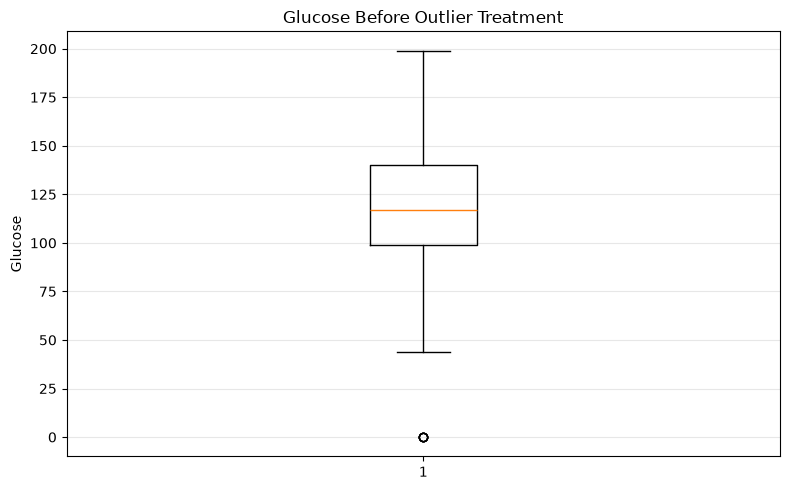

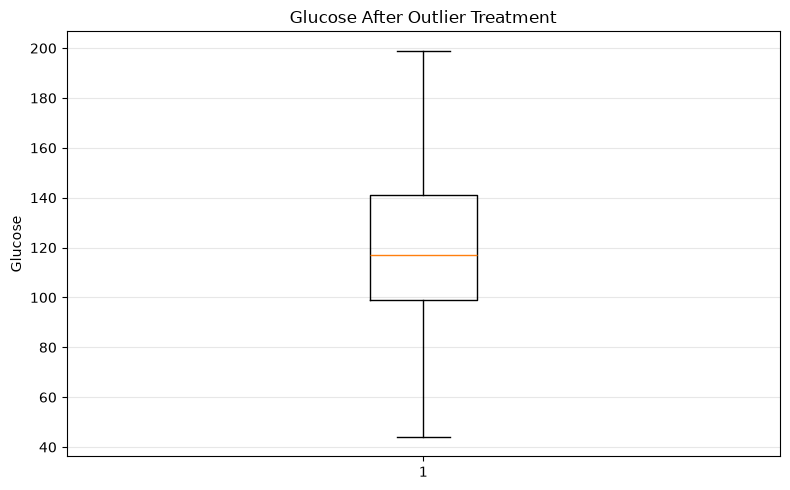

In [25]:
# ============================================
# Task 4.7 – Treat Outliers Carefully
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# 1. Create a cleaned COPY
# --------------------------------------------

diabetes_clean = diabetes.copy()

# Feature selected for outlier treatment
feature = "Glucose"

# --------------------------------------------
# 2. Calculate IQR boundaries
# --------------------------------------------

Q1 = diabetes_clean[feature].quantile(0.25)
Q3 = diabetes_clean[feature].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Glucose IQR boundaries:")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# --------------------------------------------
# 3. Remove only the justified outliers
# --------------------------------------------

before_rows = len(diabetes_clean)

diabetes_clean = diabetes_clean[
    (diabetes_clean[feature] >= lower_bound) &
    (diabetes_clean[feature] <= upper_bound)
].copy()

after_rows = len(diabetes_clean)

print("\nRows before treatment:", before_rows)
print("Rows after treatment:", after_rows)
print("Rows removed:", before_rows - after_rows)


# --------------------------------------------
# 4. Compare statistics BEFORE and AFTER
# --------------------------------------------

comparison = pd.DataFrame({
    "Before": [
        diabetes[feature].mean(),
        diabetes[feature].median(),
        diabetes[feature].std()
    ],
    "After": [
        diabetes_clean[feature].mean(),
        diabetes_clean[feature].median(),
        diabetes_clean[feature].std()
    ]
}, index=[
    "Mean",
    "Median",
    "Standard Deviation"
])

print("\n===== BEFORE VS AFTER STATISTICS =====")
print(comparison)


# --------------------------------------------
# 5. Visualization BEFORE treatment
# --------------------------------------------

plt.figure(figsize=(8, 5))

plt.boxplot(
    diabetes[feature].dropna()
)

plt.title("Glucose Before Outlier Treatment")
plt.ylabel("Glucose")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# --------------------------------------------
# 6. Visualization AFTER treatment
# --------------------------------------------

plt.figure(figsize=(8, 5))

plt.boxplot(
    diabetes_clean[feature].dropna()
)

plt.title("Glucose After Outlier Treatment")
plt.ylabel("Glucose")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Justification for Outlier Treatment

For this exercise, I removed the five `Glucose = 0` observations identified by the IQR method. These values were already identified as potentially invalid in Task 4.1 because a glucose measurement of zero is not physiologically realistic. I created a separate `diabetes_clean` dataframe so that the original dataset was not modified. The mean increased from 120.89 to 121.69, while the median remained 117.00 and the standard deviation decreased from 31.97 to 30.54.

### **Task 4.8 – Diabetes Reflection**

Answer all questions:

1. What is an outlier?
2. What are at least three possible causes of outliers?
3. Which variables showed the clearest visual outliers?
4. How many observations were flagged by the Z-Score method?
5. How many were flagged by the IQR method?
6. Why can Z-Score and IQR produce different results?
7. When should an outlier be retained?
8. When might removing an outlier be justified?
9. How did removal affect the descriptive statistics?
10. How could untreated outliers affect a downstream ML model?

### Task 4.8 – Outlier Reflection

**1. What is an outlier?**  
An outlier is an observation that is unusually far from the other observations in a dataset. It may be a very high or very low value compared with the general pattern of the data.

**2. What are at least three possible causes of outliers?**  
Outliers can be caused by:
- Data-entry or measurement errors.
- Equipment or sensor errors.
- Genuine but unusual observations.
- Differences in the population or sampling process.
- Incorrect data collection or recording.

**3. Which variables showed the clearest visual outliers?**  
Based on the box plots, `Insulin` and `SkinThickness` showed some of the clearest visual outliers. Other variables, including `Pregnancies`, `BMI`, and `Age`, also contained observations outside their box-plot whiskers.

**4. How many observations were flagged by the Z-Score method?**  
UUsing the Glucose feature and the threshold |z| > 3, 5 observations were flagged as potential outliers.

**5. How many were flagged by the IQR method?**  
Using the Glucose feature and the 1.5 × IQR rule, 5 observations were flagged as potential outliers.

**6. Why can Z-Score and IQR produce different results?**  
The two methods use different measures of spread. Z-score uses the mean and standard deviation, while IQR uses the first and third quartiles. Z-score can be affected by extreme values and works better when data is approximately normally distributed. IQR is more resistant to skewed data and extreme observations.

**7. When should an outlier be retained?**  
An outlier should be retained when it represents a legitimate observation and is not the result of an error. Removing valid unusual observations could cause important information to be lost and may make the dataset less representative.

**8. When might removing an outlier be justified?**  
Removing an outlier may be justified when there is evidence that it resulted from a data-entry mistake, measurement error, equipment problem, or another clearly identified data-quality issue. Removal should be based on evidence rather than simply because the value is unusual.

**9. How did removal affect the descriptive statistics?**  
Removing the potential `Glucose` outliers changed the mean and standard deviation more noticeably than the median. Extreme values can have a strong influence on the mean and standard deviation, while the median is more resistant to extreme observations. The cleaned dataset also contained fewer rows.

**10. How could untreated outliers affect a downstream ML model?**  
Untreated outliers can distort statistical relationships, influence model parameters, increase prediction error, and affect algorithms that are sensitive to extreme values. They can also affect scaling and distance-based methods. However, removing valid outliers can also hurt a model, so outliers should be investigated before treatment.

# **Final Validation and Submission Checklist**

Before submitting:

- [ ] All four required sections are in this single notebook.
- [ ] PEW uses `pd.melt()` or `DataFrame.melt()`.
- [ ] Billboard uses `melt()` and Pandas string manipulation.
- [ ] Cars demonstrates missing-value analysis, dropping, imputation, duplicates, and validation.
- [ ] Diabetes includes box plot, scatter plot, Z-Score, and IQR.
- [ ] Every required visualization has a meaningful title and axis labels.
- [ ] Reflection questions are answered in Markdown.
- [ ] Data is loaded using relative paths from a clearly named data folder.
- [ ] `README.md`, `requirements.txt`, and `.gitignore` are included.
- [ ] There are no unnecessary `!pip install` cells.
- [ ] You restarted the kernel and successfully ran **Run All** from top to bottom.

# **General Guidelines**

## Expected Observations

### PEW
- Income categories are encoded as column headings in the original wide dataset.
- `melt()` should preserve religion as an identifier while moving income categories into rows.
- The long form is easier to group, filter, and visualize.

### Billboard
- Weekly rankings are stored across repeated week columns.
- `melt()` converts weekly columns into observations.
- Week labels usually require string cleanup/extraction before numeric analysis.
- Missing rankings often indicate that a song was not ranked in that week and should not automatically be imputed.

### Cars
- Students should inspect before deleting the first row; removal should be evidence-based.
- Some numeric-looking columns may require conversion from `object`.
- Mean imputation is sensitive to skew/outliers; median can be more robust.
- Dropping every column containing a missing value is generally too destructive when missingness is small.

### Diabetes
- Box plots and IQR are closely related but students should understand that visualization and rule-based detection serve different purposes.
- Z-Score works best when a roughly normal-distribution assumption is reasonable.
- IQR is more robust for skewed distributions.
- Outliers should not be removed automatically without context.

## Common Mistakes

- Using absolute paths such as `C:\Users\...`.
- Treating `melt()` as equivalent to simply renaming columns.
- Cleaning Billboard week labels without converting the result to numeric.
- Filling every missing value with zero.
- Dropping data without first reporting the effect.
- Using `|z| > 2` when the assignment specifies `|z| > 3`.
- Computing IQR incorrectly or reversing the lower/upper bound formulas.
- Removing outliers from the original dataframe and losing the baseline for comparison.
- Producing plots without titles, labels, or interpretation.
- Adding `!pip install` cells even though the project includes `requirements.txt`.

## Suggested Instructor Solutions / Checks

- Accept both `pd.melt(df, ...)` and `df.melt(...)`.
- Accept logically equivalent Pandas string-cleaning approaches.
- For missing values, grade the quality of the justification, not only the specific method selected.
- Require evidence that the notebook runs sequentially.
- Confirm that each data file is loaded from the submitted project using relative paths.

## Stretch Challenges

1. Build reusable functions for tidying and cleaning.
2. Compare multiple imputation strategies quantitatively.
3. Use `ColumnTransformer` or a Scikit-Learn preprocessing pipeline.
4. Compare outlier treatment before/after scaling.
5. Investigate how removing outliers changes a simple regression model.
6. Export cleaned datasets to a `processed/` subfolder without overwriting raw data.